In [3]:
import os, sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))

import pandas as pd
from mercado.base_precos import carregar_base, carregar_catalogo, limpar

obs = limpar(carregar_base(), carregar_catalogo())
obs.shape

(15739, 16)

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# mediana de cada produto, em cada rede, em cada rodada
prm = (obs.groupby(["id_produto", "rede", "__mes"])["preco_regular"]
          .median().rename("preco").reset_index())

# mediana entre redes = referência do produto na rodada
ref_mes = prm.groupby(["id_produto", "__mes"])["preco"].median().unstack("id_produto")

# nome curto para os gráficos
nome = (obs.groupby("id_produto")["descricao"].agg(lambda s: s.mode().iloc[0])
           .str.replace(r"\s+", " ", regex=True).str.slice(0, 35))
grupo = obs.groupby("id_produto")["grupo"].first()

ref_mes.shape   # (rodadas, produtos): esperado (33, 50)

(33, 50)

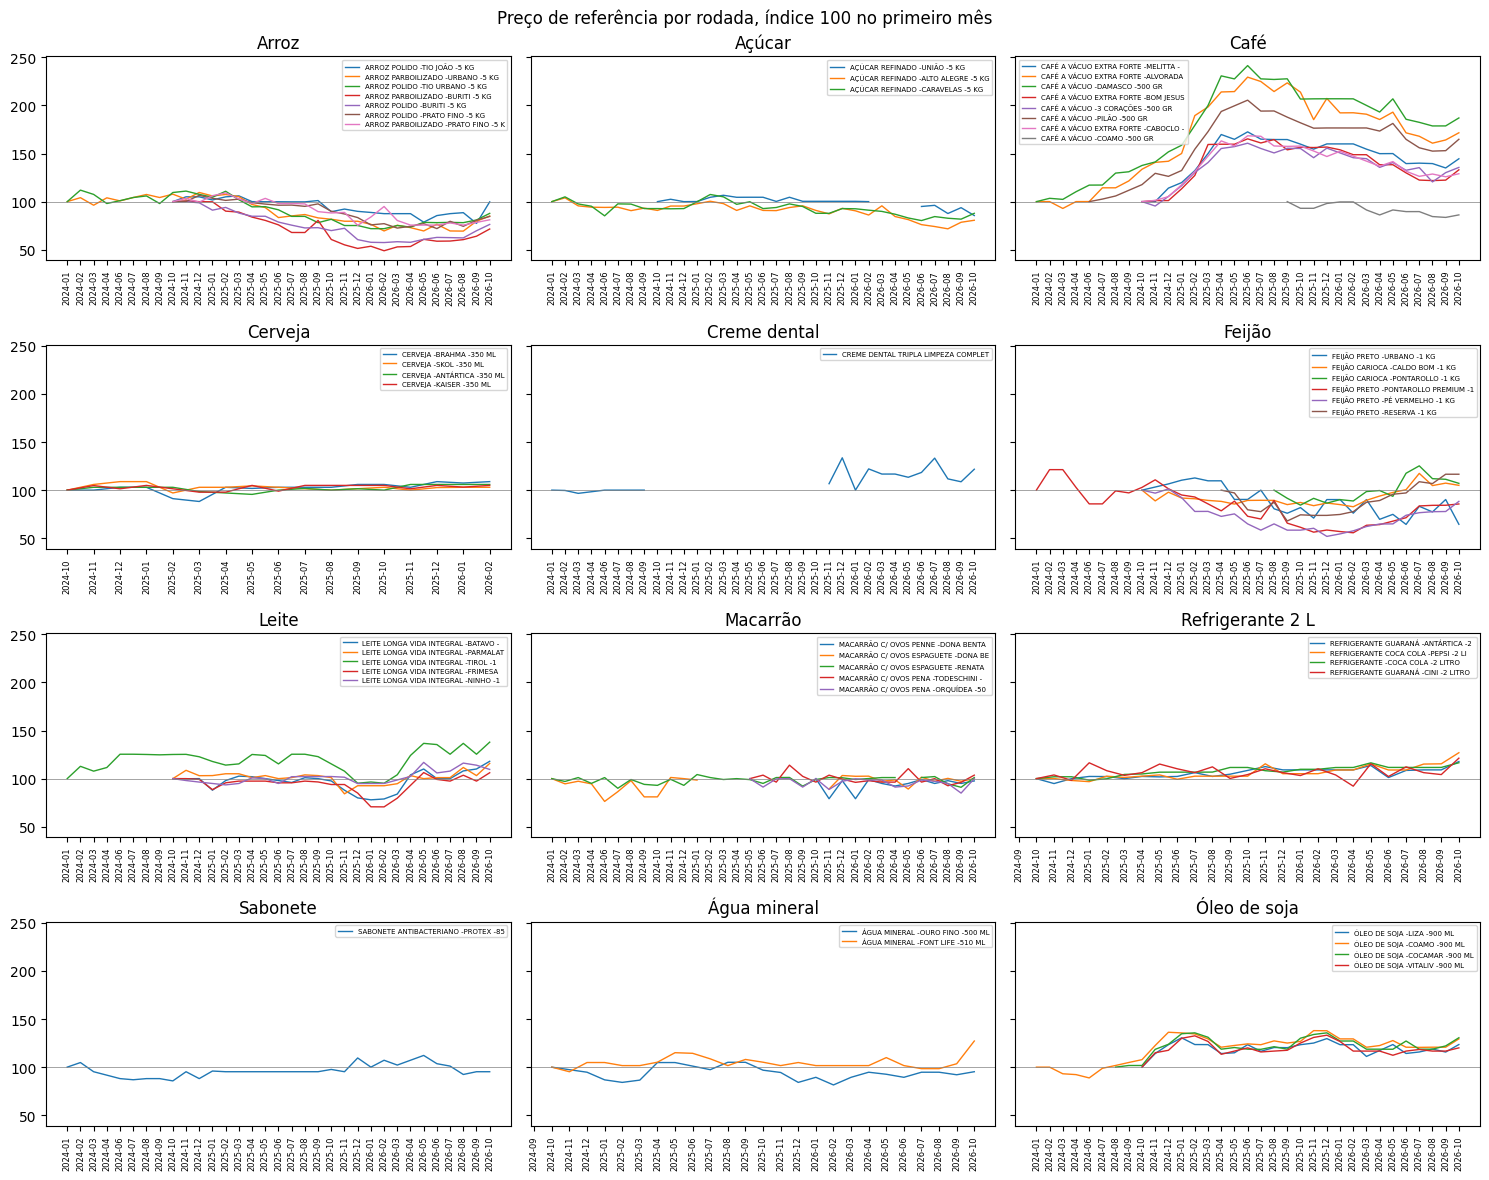

In [5]:
indice = ref_mes.apply(lambda s: s / s.dropna().iloc[0] * 100)

grupos = sorted(grupo.unique())
fig, axes = plt.subplots(4, 3, figsize=(15, 12), sharey=True)
for ax, g in zip(axes.flat, grupos):
    for pid in grupo[grupo == g].index:
        ax.plot(indice.index, indice[pid], label=nome[pid], linewidth=1)
    ax.axhline(100, color="grey", linewidth=0.5)
    ax.set_title(g)
    ax.tick_params(axis="x", rotation=90, labelsize=6)
    ax.legend(fontsize=5)
plt.suptitle("Preço de referência por rodada, índice 100 no primeiro mês")
plt.tight_layout()

In [6]:
var = pd.DataFrame({
    "grupo": grupo,
    "produto": nome,
    "primeiro": ref_mes.apply(lambda s: s.dropna().iloc[0]),
    "ultimo": ref_mes.apply(lambda s: s.dropna().iloc[-1]),
    "meses": ref_mes.notna().sum(),
})
var["variacao_%"] = ((var["ultimo"] / var["primeiro"] - 1) * 100).round(1)
var.sort_values("variacao_%", ascending=False)

,grupo,produto,primeiro,ultimo,meses,variacao_%
id_produto,,,,,,
7896019112116,Café,CAFÉ A VÁCUO -DAMASCO -500 GR,14.490,27.100,33,87.0
7896016700149,Café,CAFÉ A VÁCUO EXTRA FORTE -ALVORADA,13.980,23.990,33,71.6
7896089011357,Café,CAFÉ A VÁCUO -PILÃO -500 GR,16.980,27.990,29,64.8
7891021006934,Café,CAFÉ A VÁCUO EXTRA FORTE -MELITTA -,19.990,28.900,25,44.6
7896256600223,Leite,LEITE LONGA VIDA INTEGRAL -TIROL -1,3.980,5.490,33,37.9
7896045102440,Café,CAFÉ A VÁCUO -3 CORAÇÕES -500 GR,19.900,26.980,25,35.6
7896035733449,Café,CAFÉ A VÁCUO EXTRA FORTE -BOM JESUS,18.780,24.990,25,33.1
7897001010014,Óleo de soja,ÓLEO DE SOJA -COCAMAR -900 ML,5.890,7.690,27,30.6
7896279600538,Óleo de soja,ÓLEO DE SOJA -COAMO -900 ML,5.790,7.490,33,29.4


In [10]:
mud = ref_mes.pct_change(fill_method=None)
corr = mud.corr(method="spearman", min_periods=12)
corr = corr.rename_axis(index="sku_a", columns="sku_b")      # nomes diferentes para linhas e colunas

pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().rename("corr").reset_index())
pares.columns = ["sku_a", "sku_b", "corr"]
pares["n_meses"] = [mud[[a, b]].dropna().shape[0] for a, b in zip(pares.sku_a, pares.sku_b)]
pares["prod_a"] = pares.sku_a.map(nome); pares["prod_b"] = pares.sku_b.map(nome)
pares["mesmo_grupo"] = pares.sku_a.map(grupo) == pares.sku_b.map(grupo)

print("pares avaliados:", len(pares))
pares.sort_values("corr", ascending=False).head(15)[["prod_a", "prod_b", "corr", "n_meses", "mesmo_grupo"]]

pares avaliados: 1150


,prod_a,prod_b,corr,n_meses,mesmo_grupo
13,CAFÉ A VÁCUO EXTRA FORTE -MELITTA -,CAFÉ A VÁCUO -DAMASCO -500 GR,0.829417,24,True
581,CAFÉ A VÁCUO -DAMASCO -500 GR,CAFÉ A VÁCUO -COAMO -500 GR,0.808804,13,True
733,ÓLEO DE SOJA -LIZA -900 ML,ÓLEO DE SOJA -COAMO -900 ML,0.804958,24,True
126,LEITE LONGA VIDA INTEGRAL -BATAVO -,LEITE LONGA VIDA INTEGRAL -FRIMESA,0.796252,24,True
1127,ÓLEO DE SOJA -COCAMAR -900 ML,ÓLEO DE SOJA -VITALIV -900 ML,0.765577,24,True
571,CAFÉ A VÁCUO -DAMASCO -500 GR,CAFÉ A VÁCUO -PILÃO -500 GR,0.746579,28,True
535,CAFÉ A VÁCUO EXTRA FORTE -ALVORADA,CAFÉ A VÁCUO -3 CORAÇÕES -500 GR,0.741739,24,True
636,MACARRÃO C/ OVOS PENA -TODESCHINI -,REFRIGERANTE GUARANÁ -CINI -2 LITRO,0.740650,17,False
695,CAFÉ A VÁCUO EXTRA FORTE -BOM JESUS,CAFÉ A VÁCUO -PILÃO -500 GR,0.740644,24,True
34,CAFÉ A VÁCUO EXTRA FORTE -MELITTA -,CAFÉ A VÁCUO -COAMO -500 GR,0.739669,13,True


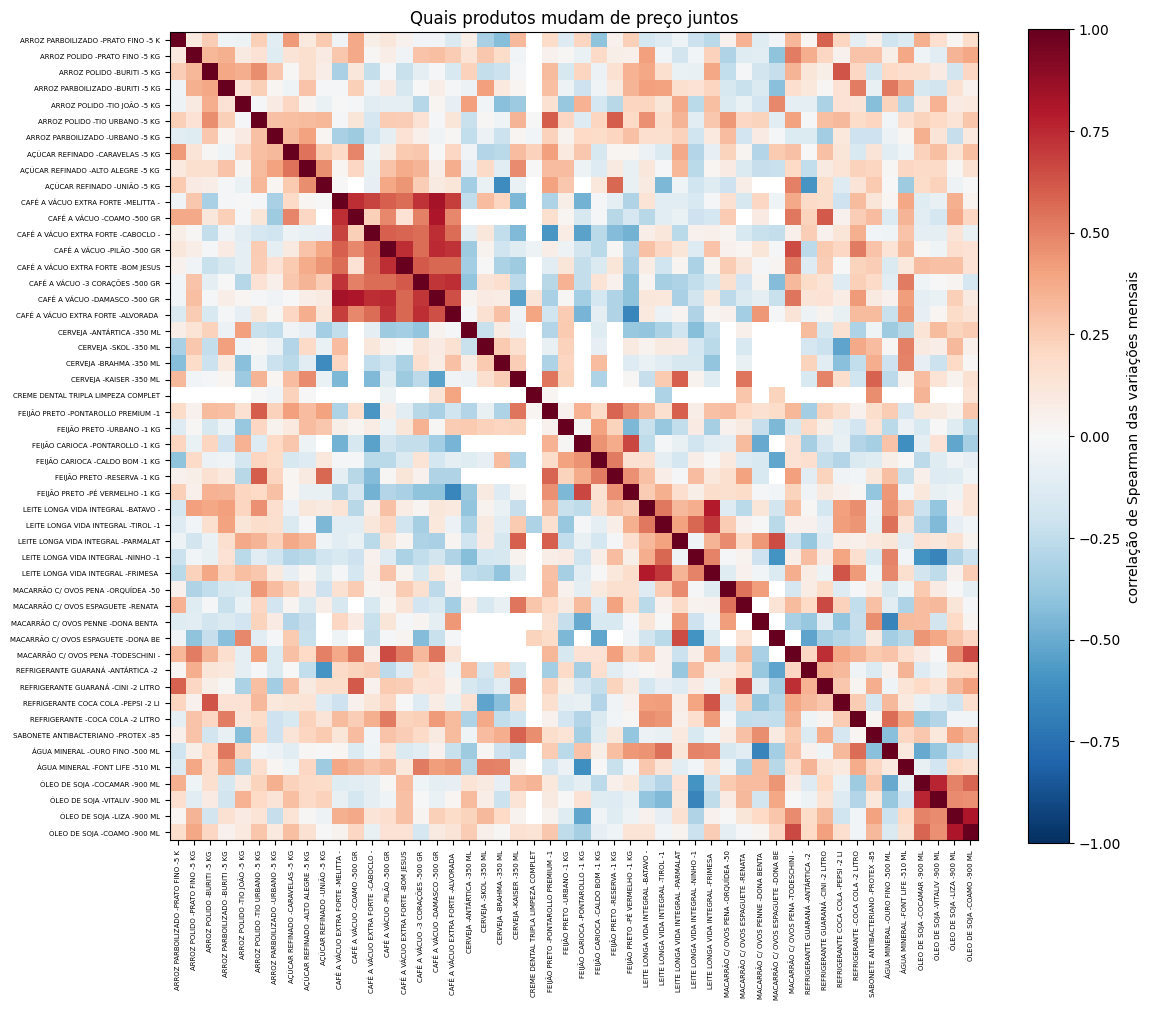

In [8]:
ordem = grupo.sort_values().index
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr.loc[ordem, ordem], cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(ordem))); ax.set_xticklabels(nome[ordem], rotation=90, fontsize=5)
ax.set_yticks(range(len(ordem))); ax.set_yticklabels(nome[ordem], fontsize=5)
plt.colorbar(im, label="correlação de Spearman das variações mensais")
plt.title("Quais produtos mudam de preço juntos")
plt.tight_layout()

In [14]:
   prm = prm.merge(ref_mes.stack().rename("ref").reset_index(), on=["__mes", "id_produto"])
   prm["indice"] = prm["preco"] / prm["ref"] * 100

   redes = (prm.groupby("rede")
               .agg(indice_mediano=("indice", "median"),
                    produtos=("id_produto", "nunique"),
                    observacoes=("indice", "size"))
               .query("produtos >= 15")
               .sort_values("indice_mediano"))
   redes["indice_mediano"] = redes["indice_mediano"].round(1)
   redes

,indice_mediano,produtos,observacoes
rede,,,
Max Atacadista,94.0,46,185
Condor,95.6,50,1086
Circuito,95.7,36,76
Super Muffato,97.1,50,994
Atacadão,97.2,47,536
Agricer,97.6,43,227
Max Muffato,98.6,18,20
Armazem da Maria,98.7,46,179
Assaí,98.9,47,617


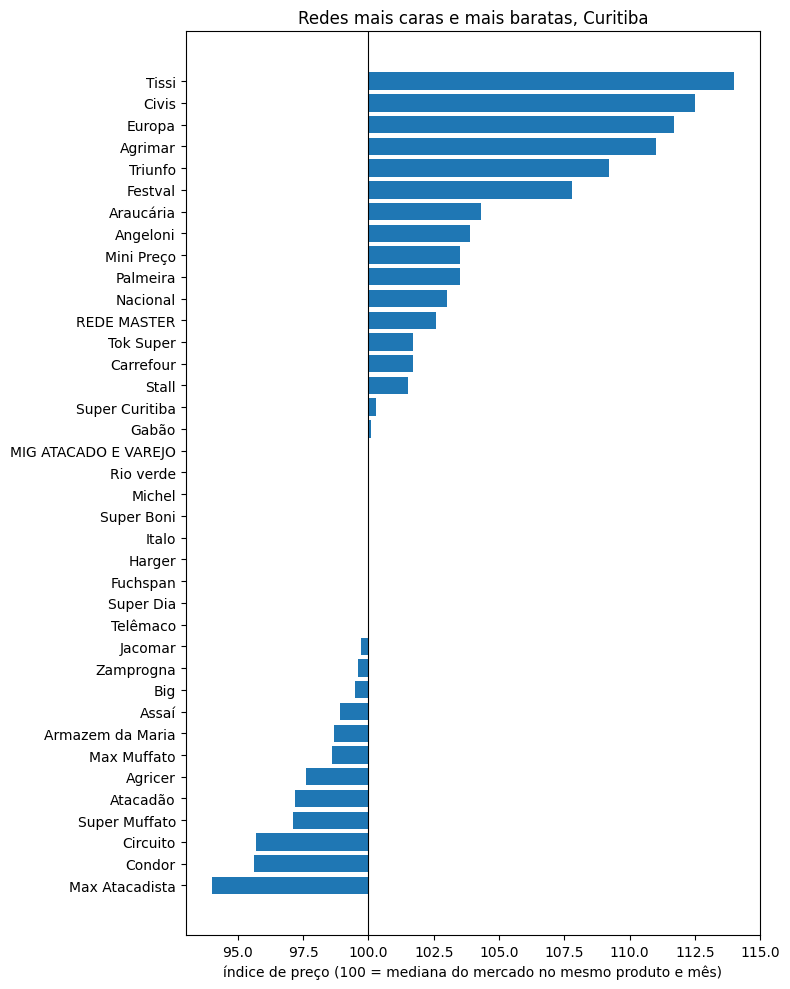

In [15]:
fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(redes.index, redes["indice_mediano"] - 100, left=100)
ax.axvline(100, color="black", linewidth=0.8)
ax.set_xlabel("índice de preço (100 = mediana do mercado no mesmo produto e mês)")
ax.set_title("Redes mais caras e mais baratas, Curitiba")
plt.tight_layout()

In [16]:
prm["grupo"] = prm["id_produto"].map(grupo)
mapa = prm[prm.rede.isin(redes.index)].pivot_table(index="rede", columns="grupo", values="indice", aggfunc="median")
mapa.loc[redes.index].round(0)

grupo,Arroz,Açúcar,Café,Cerveja,Creme dental,Feijão,Leite,Macarrão,Refrigerante 2 L,Sabonete,Água mineral,Óleo de soja
rede,,,,,,,,,,,,
Max Atacadista,90.0,91.0,93.0,94.0,98.0,99.0,100.0,80.0,93.0,92.0,75.0,98.0
Condor,94.0,91.0,94.0,100.0,97.0,94.0,100.0,95.0,97.0,93.0,91.0,99.0
Circuito,96.0,97.0,95.0,91.0,84.0,106.0,99.0,88.0,94.0,103.0,63.0,92.0
Super Muffato,98.0,95.0,96.0,97.0,100.0,97.0,100.0,96.0,94.0,97.0,100.0,99.0
Atacadão,100.0,96.0,96.0,98.0,97.0,98.0,97.0,92.0,100.0,90.0,NaN,99.0
Agricer,90.0,100.0,98.0,95.0,94.0,100.0,97.0,100.0,100.0,98.0,100.0,94.0
Max Muffato,94.0,NaN,96.0,NaN,90.0,105.0,107.0,67.0,100.0,NaN,NaN,99.0
Armazem da Maria,100.0,99.0,98.0,98.0,118.0,95.0,98.0,100.0,98.0,100.0,NaN,99.0
Assaí,100.0,99.0,100.0,100.0,98.0,100.0,93.0,97.0,100.0,93.0,81.0,97.0


## Conclusoes

Variação entre primeiro e último mês não controla o período: produtos com séries mais curtas não são comparáveis direto.
Variações mensais carregam ruído do rodízio de lojas.
Com 1.150 pares, correlações altas por acaso são esperadas; só confiar nas que têm explicação de negócio.
Correlação não é causa.
Índices de redes com poucas observações ou de grupos com 1 SKU são frágeis.